# Project 1: VaR and ES -- Estimation, Backtesting, and Model Comparison

**Names of all group members:**
- Anaki Léa Oviedo Pinto (anaki.oviedopinto@epfl.ch)
- Firstname Lastname (email@example.com)

---

## 0) Setup

Creates necessary folders, sets parameters, and fixes the random seed. Keep this seed fixed; the whole run must be reproducible from it.

In [282]:
# If a package import fails, install it in your environment, e.g.:
# %pip install arch statsmodels

import os
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
from pathlib import Path

PROJECT_DIR = Path.cwd()
DATA_FILE = PROJECT_DIR / "QRM_2026_Project_prices.csv"   # provided with the project; do not re-download
OUT_DIR = PROJECT_DIR / "output"
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Parameters
TICKERS = ["AAPL", "META", "JPM"]   # every question is run separately on each stock
WINDOW = 504                        # estimation window of every model, in trading days (Questions 2-5)
EVAL_START = 504                    # Questions 3-5: forecast days are all days after the first 504
REFIT = 21                          # Questions 4-5: re-estimate every this many trading days
ALPHAS = [0.975, 0.99]              # confidence levels used throughout Questions 2-5
DEEP_ALPHA = 0.999                  # Question 6: the extreme level EVT is asked for
M_SIM = 10_000                      # Questions 3(c), 4(d): Acerbi-Szekely simulated samples
LB_LAGS = 10                        # Ljung-Box H in Questions 1 and 4
NW_LAGS = 10                        # Newey-West truncation lag of the Diebold-Mariano test
SEED = 0                            # fix this, state it in the report, do not change it later

rng = np.random.default_rng(SEED)
print("Project dir:", PROJECT_DIR)


Project dir: /Users/anaki.oviedo/Desktop/QRM/Project


## 1) Data

The prices were downloaded once with `yfinance` (adjusted closes, 2 January 2013 to 30 June 2026,
downloaded on 28 October 2026) and are provided as `QRM_2026_Project_prices.csv`. Read this file;
do not download the data again, since Yahoo revises adjusted prices back in time.

In [283]:
price_df = pd.read_csv(DATA_FILE, index_col=0, parse_dates=True)[TICKERS]
print(price_df.shape, price_df.index[0].date(), "to", price_df.index[-1].date())   # (3393, 3)

(3393, 3) 2013-01-02 to 2026-06-30


## 2) Log-returns and losses

Construct $R_t=\log(P_t/P_{t-1})$ for each ticker. The log-loss used everywhere in this project is
$L_t=-R_t$. Every question is run separately on each of the three columns; there is no portfolio.

In [284]:
returns = np.log(price_df / price_df.shift(1)).dropna()
losses = -returns

print(returns.shape, returns.index[0].date(), "to", returns.index[-1].date())   # (3392, 3)
returns.head()

(3392, 3) 2013-01-03 to 2026-06-30


,AAPL,META,JPM
Date,,,
2013-01-03,-0.012703,-0.008248,-0.002017
2013-01-04,-0.028250,0.035029,0.017569
2013-01-07,-0.005900,0.022689,0.001101
2013-01-08,0.002688,-0.012312,0.001980
2013-01-09,-0.015752,0.051311,-0.000660


## Question 1 -- Stylized facts

For each stock: (a) plot the return series; (b) ACF of returns and of squared returns, and the
Ljung-Box test with $H$ = `LB_LAGS` on both (`statsmodels.stats.diagnostic.acorr_ljungbox`);
(c) QQ-plot and Jarque-Bera.

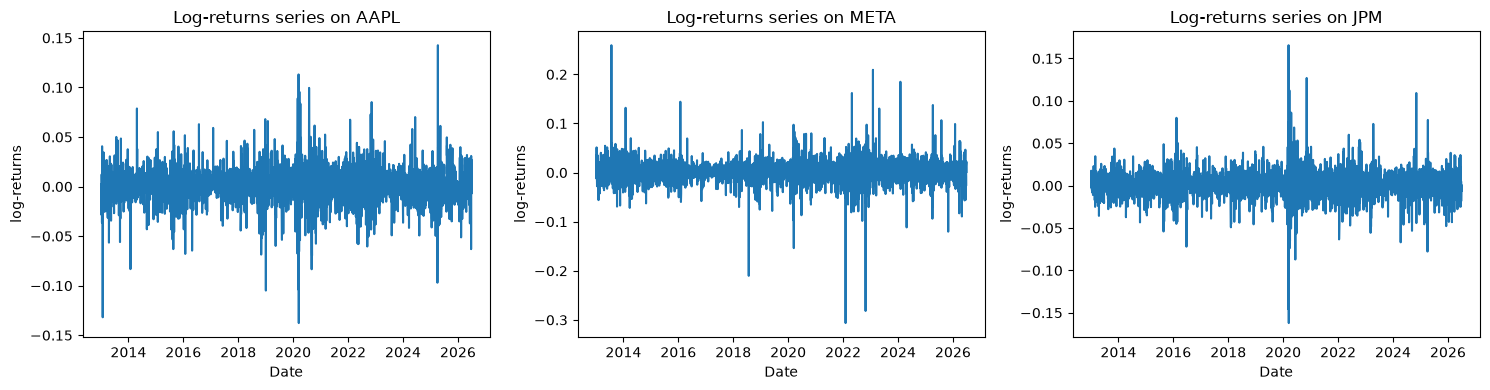

In [285]:
# Question 1
#a) 
fig, axes = plt.subplots(1,3, figsize= (15,4)) #sharey=True
for col,ax in zip(TICKERS, axes):
    ax.plot(returns[col])
    ax.set_title(f"Log-returns series on {col}")
    ax.set_xlabel('Date')
    ax.set_ylabel('log-returns')
plt.subplots_adjust(wspace=0.25)
#plt.ylim([-0.25,0.15])

plt.tight_layout()
plt.savefig(OUT_DIR / "fig_Q1a_returns.png", dpi=200, bbox_inches="tight")
plt.show()

In [286]:
#b)
rows = []
for col in TICKERS:
    X = returns[col].to_numpy()
    mean = np.mean(X)
    for h in range(1,31):
        cov = (1/len(X)) * np.sum((X[:-h] - mean) * (X[h:] - mean))
        autocorr = cov/np.var(X) 
        rows.append((col,h,autocorr))

results = pd.DataFrame(rows,columns=['Stock', 'Lags', 'ACF'])

#fig, axes = plt.subplots(1,3,figsize=(15,4))

#for ax,col in zip(axes, TICKERS):
#    cols_res = results.loc[results.Stock == col]['ACF']
#    ax.plot(results.loc[results.Stock == col]['Lags'], cols_res, 'o-', mec='r',mfc='r')
#    ax.set_xlabel('Lags')
#    ax.set_ylabel('Autocorrelation')
#    ax.set_title(f"Autocorrelation Function of {col}")

#plt.subplots_adjust(wspace=0.3)
#plt.show()

In [287]:
rows = []
for col in TICKERS:
    X = (returns[col]**2).to_numpy() 
    mean = np.mean(X)
    for h in range(1,31):
        cov = (1/len(X)) * np.sum((X[:-h] - mean) * (X[h:] - mean))
        autocorr = cov/np.var(X) 
        rows.append((col,h,autocorr))

results_squared = pd.DataFrame(rows,columns=['Stock', 'Lags', 'ACF'])

#fig, axes = plt.subplots(1,3,figsize=(15,4))

#for ax,col in zip(axes, TICKERS):
#    cols_res = results_squared.loc[results_squared.Stock == col]['ACF']
#    ax.bar(results_squared.loc[results_squared.Stock == col]['Lags'], cols_res, width=0.4)
#    ax.axhline(0, color='black', linewidth=1)
#    ax.set_xlabel('Lags')
#    ax.set_ylabel('Autocorrelation')
#    ax.set_title(f"Autocorrelation Function of {col}")

#plt.subplots_adjust(wspace=0.3)
#plt.show()

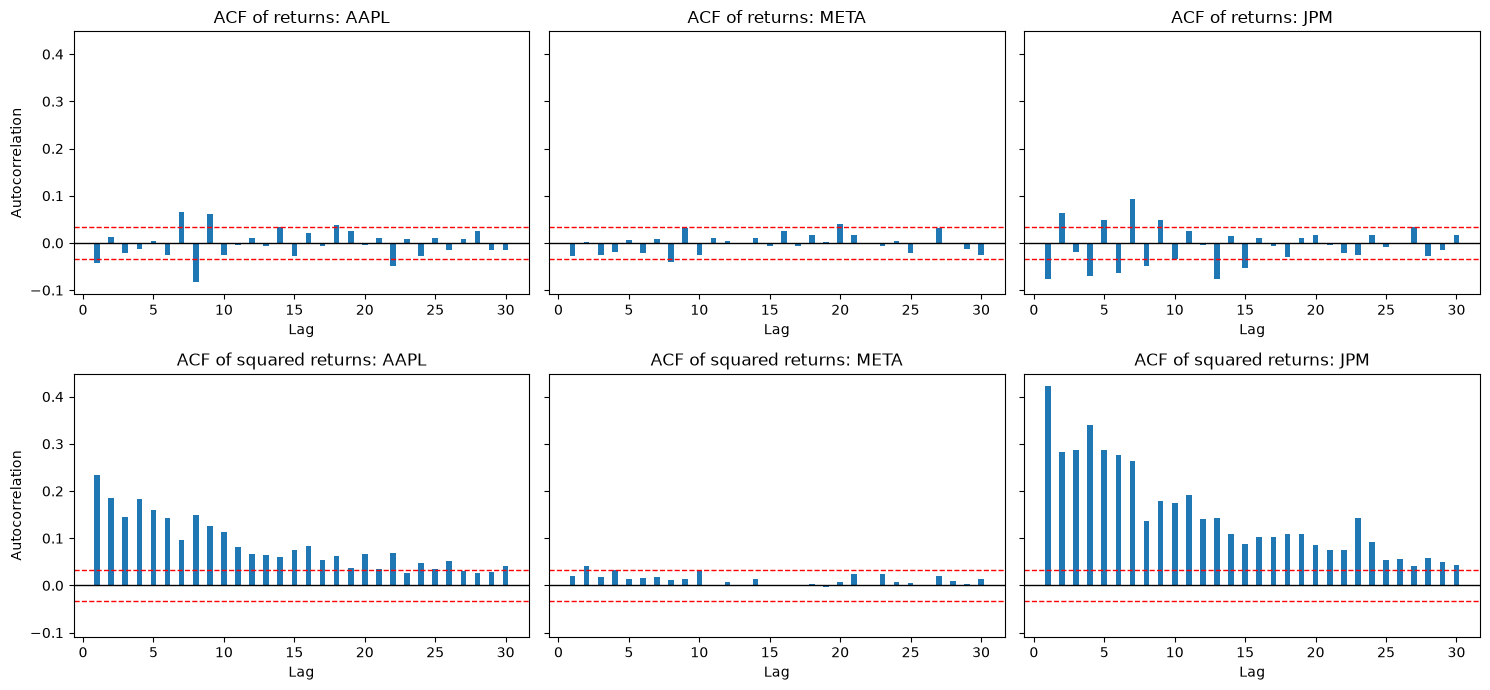

In [288]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharey=True)

for j, col in enumerate(TICKERS):
    n = len(returns[col])
    band = 1.96 / np.sqrt(n)

    for i, (res, title) in enumerate([(results, "returns"), (results_squared, "squared returns")]):
        ax = axes[i, j]
        d = res[res.Stock == col]
        ax.bar(d['Lags'], d['ACF'], width=0.4)
        ax.axhline(0, color='black', lw=1)
        ax.axhline(band, color='red', ls='--', lw=1)
        ax.axhline(-band, color='red', ls='--', lw=1)
        ax.set_title(f"ACF of {title}: {col}")
        ax.set_xlabel('Lag')
        if j == 0:
            ax.set_ylabel('Autocorrelation')

plt.tight_layout()
plt.savefig(OUT_DIR / "fig_Q1b_returns.png", dpi=200, bbox_inches="tight")
plt.show()

In [290]:
#Ljung-Box test normal series
#QLB >χ2H,0.95 (e.g. 18.3 for H = 10) Reject H0
#j = np.arange(1,11)
#test_result = {'AAPL':0,'META':0,'JPM':0}
#for stock in TICKERS:
#    Y = results[results.Stock == stock].ACF.to_numpy()
#    n = len(returns[stock])
#    Q_LB = n * (n + 2) * np.sum((Y[:LB_LAGS])**2 / (n - j))
    #test_result[stock] = Q_LB
#    p = 1 - stats.chi2.cdf(Q_LB, LB_LAGS)       # p-value, chi2 à H=10 ddl
#    print(f"Ljung-Box {stock}: Q={Q_LB:.2f}, p={p:.4g}")

In [291]:
#Ljung-Box test squared series
#j = np.arange(1,11)
#test_result_squared = {'AAPL':0,'META':0,'JPM':0}
#for stock in TICKERS:
#    Y = results_squared[results_squared.Stock == stock].ACF.to_numpy()
#    n = len(returns[stock])
#    Q_LB = n * (n + 2) * np.sum((Y[:LB_LAGS])**2 / (n - j))
    #test_result_squared[stock] = Q_LB
#    p = 1 - stats.chi2.cdf(Q_LB, LB_LAGS)       # p-value, chi2 à H=10 ddl
#    print(f"Ljung-Box {stock}: Q={Q_LB:.2f}, p={p:.4g}")


In [292]:
# Ljung-Box (H = LB_LAGS) on returns and squared returns
lags = np.arange(1, LB_LAGS + 1)
crit = stats.chi2.ppf(0.95, LB_LAGS)          # 18.307 pour H = 10

rows = []
for stock in TICKERS:
    n = len(returns[stock])                    # 3392, pas le nombre de lags
    for label, res in [("returns", results), ("squared returns", results_squared)]:
        rho = res[res.Stock == stock].ACF.to_numpy()[:LB_LAGS]
        Q = n * (n + 2) * np.sum(rho**2 / (n - lags))
        p = stats.chi2.sf(Q, LB_LAGS)          # = 1 - cdf, plus précis pour les petites p-values
        rows.append((stock, label, Q, crit, p, "Reject" if Q > crit else "Do not reject"))

results_LB = pd.DataFrame(rows, columns=['Stock', 'Series', 'Q_LB', 'chi2_95', 'p_value', 'Decision'])
print(results_LB.round(4))

#Save results
results_LB.to_csv(OUT_DIR / "tab_Q1b_LB.csv", index=False)

  Stock           Series       Q_LB  chi2_95  p_value Decision
0  AAPL          returns    64.4300   18.307   0.0000   Reject
1  AAPL  squared returns   849.2934   18.307   0.0000   Reject
2  META          returns    19.5762   18.307   0.0335   Reject
3  META  squared returns    19.0975   18.307   0.0390   Reject
4   JPM          returns   124.2931   18.307   0.0000   Reject
5   JPM  squared returns  2607.4927   18.307   0.0000   Reject


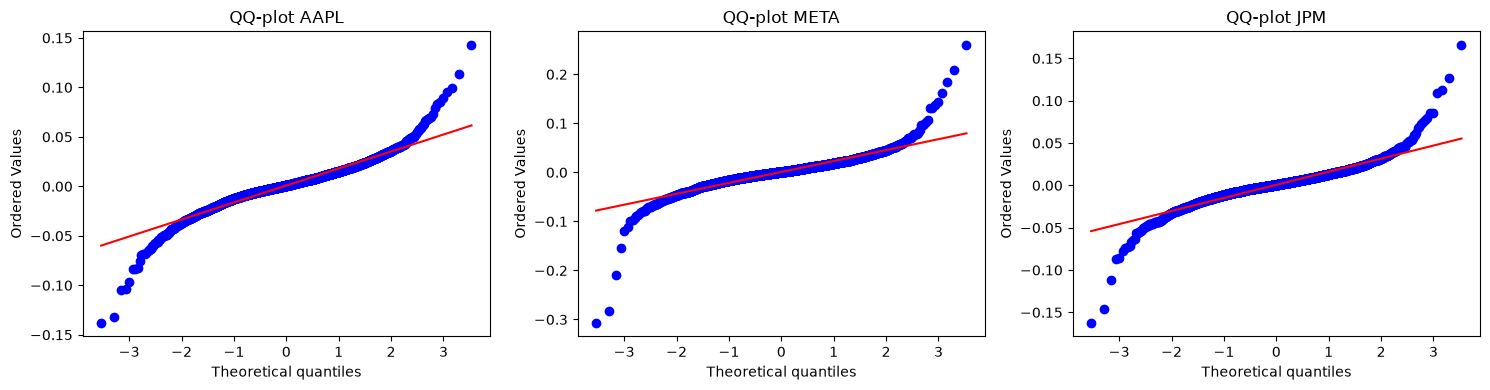

In [293]:
#c)
fig, axes = plt.subplots(1,3, figsize=(15,4))
for col,ax in zip(TICKERS, axes):
    measurements = returns[col]  
    stats.probplot(measurements, dist="norm", plot=ax)
    ax.set_title(f"QQ-plot {col}")

plt.subplots_adjust(wspace=0.3)
plt.tight_layout()
plt.savefig(OUT_DIR / "fig_Q1c_returns.png", dpi=200, bbox_inches="tight")
plt.show()

In [294]:

rows = []

for col in TICKERS:
    X = returns[col]
    JB, pvalue = stats.jarque_bera(X)
    rows.append((col, JB, pvalue))

results_JB = pd.DataFrame(rows, columns=['Stock', 'JB Statistic', 'p_value'])

print(results_JB)

#Save results
results_JB.to_csv(OUT_DIR / "tab_Q1c_JB.csv", index=False)


  Stock  JB Statistic  p_value
0  AAPL   6590.613996      0.0
1  META  84216.050984      0.0
2   JPM  23655.819050      0.0


## Question 2 -- Single-window VaR and ES estimates

For each stock, use the first `WINDOW` losses as the single estimation window for (a)-(d).

In [295]:
# Question 2
window_loss = losses.iloc[:WINDOW]          # one column per stock
losses

,AAPL,META,JPM
Date,,,
2013-01-03,0.012703,0.008248,0.002017
2013-01-04,0.028250,-0.035029,-0.017569
2013-01-07,0.005900,-0.022689,-0.001101
2013-01-08,-0.002688,0.012312,-0.001980
2013-01-09,0.015752,-0.051311,0.000660
...,...,...,...
2026-06-24,0.004154,0.008090,0.002067
2026-06-25,0.063129,0.026898,-0.004996
2026-06-26,-0.030883,-0.013503,0.018279


In [296]:
#a)
from scipy.stats import norm, t


rows = []

for stock in TICKERS:
    L = window_loss[stock].dropna()
    sorted_L = np.sort(L)[::-1]

    for alpha in ALPHAS:
        k = int(np.floor(WINDOW * (1-alpha)))

        VaR = sorted_L[k]

        ES = (
            np.sum(sorted_L[:k])
            + (WINDOW * (1-alpha) - k) * VaR
        ) / (WINDOW * (1-alpha))

        rows.append((stock, alpha, VaR, ES))

hist_results = pd.DataFrame(
    rows,
    columns=['Stock', 'Alpha', 'VaR_hist', 'ES_hist']
)



In [297]:
#b)
rows = []

for stock in TICKERS:
    L = window_loss[stock].dropna()

    mu = L.mean()
    sigma = L.std(ddof=1)

    for alpha in ALPHAS:
        q = norm.ppf(alpha)

        VaR = mu + sigma * q
        ES = mu + sigma * norm.pdf(q) / (1-alpha)

        rows.append((stock, alpha, VaR, ES))

gaussian_results = pd.DataFrame(
    rows,
    columns=['Stock', 'Alpha', 'VaR_gauss', 'ES_gauss']
)



In [298]:
#c)
rows = []

for stock in TICKERS:
    L = window_loss[stock].dropna()

    nu, loc, scale = t.fit(L)

    for alpha in ALPHAS:
        q = t.ppf(alpha, df=nu)

        VaR = loc + scale * q

        ES = loc + scale * (
            t.pdf(q, df=nu)
            * (nu + q**2)
            / ((1-alpha) * (nu-1))
        )

        rows.append((stock, alpha, VaR, ES, nu, loc, scale))

student_results = pd.DataFrame(
    rows,
    columns=['Stock', 'Alpha', 'VaR_t', 'ES_t', 'nu','loc', 'scale']
)



In [299]:
results_Q2 = (
    hist_results
    .merge(gaussian_results, on=['Stock', 'Alpha'])
    .merge(student_results, on=['Stock', 'Alpha'])
)
#Save results
results_Q2.to_csv(OUT_DIR / "tab_Q2_estimates.csv", index=False)

results_Q2

,Stock,Alpha,VaR_hist,ES_hist,VaR_gauss,ES_gauss,VaR_t,ES_t,nu,loc,scale
0,AAPL,0.975,0.029007,0.049743,0.030675,0.036733,0.029466,0.042487,4.132389,-0.001059,0.011133
1,AAPL,0.990,0.038878,0.073891,0.036549,0.041983,0.039929,0.055553,4.132389,-0.001059,0.011133
2,META,0.975,0.042346,0.055957,0.047198,0.056690,0.045408,0.063511,4.679262,-0.001308,0.017800
3,META,0.990,0.053480,0.065295,0.056403,0.064916,0.060343,0.081375,4.679262,-0.001308,0.017800
4,JPM,0.975,0.023833,0.029208,0.021980,0.026366,0.022441,0.029866,6.482710,-0.000962,0.009737
5,JPM,0.990,0.027780,0.035363,0.026233,0.030167,0.028891,0.036936,6.482710,-0.000962,0.009737


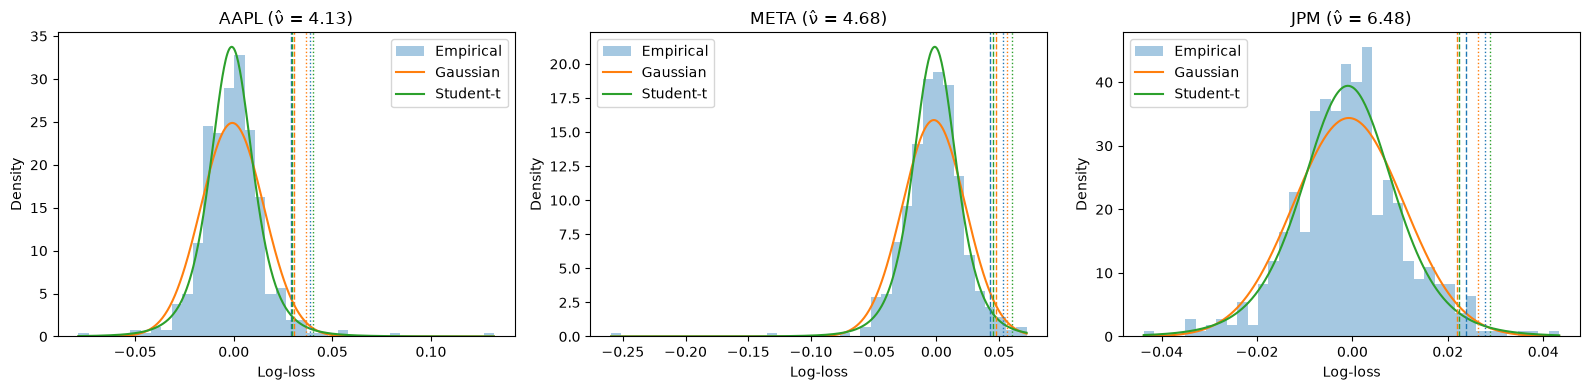

In [300]:
#d)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, stock in zip(axes, TICKERS):
    L = losses[stock].iloc[:WINDOW].dropna()

    mu = L.mean()
    sigma = L.std(ddof=1)

    # paramètres t de CETTE action
    p = student_results[student_results.Stock == stock].iloc[0]
    nu_s, loc_s, scale_s = p['nu'], p['loc'], p['scale']

    x = np.linspace(L.min(), L.max(), 500)

    ax.hist(L, bins=40, density=True, alpha=0.4, label='Empirical')
    ax.plot(x, norm.pdf(x, mu, sigma), label='Gaussian')
    ax.plot(x, t.pdf(x, nu_s, loc=loc_s, scale=scale_s), label='Student-t')

    # VaR des trois méthodes aux deux niveaux
    for alpha, ls in zip(ALPHAS, ['--', ':']):
        r = results_Q2[(results_Q2.Stock == stock) & (results_Q2.Alpha == alpha)].iloc[0]
        ax.axvline(r['VaR_hist'],  color='C0', ls=ls, lw=1)
        ax.axvline(r['VaR_gauss'], color='C1', ls=ls, lw=1)
        ax.axvline(r['VaR_t'],     color='C2', ls=ls, lw=1)

    ax.set_title(f"{stock} (ν̂ = {nu_s:.2f})")
    ax.set_xlabel('Log-loss')
    ax.set_ylabel('Density')
    ax.legend()

plt.tight_layout()
plt.savefig(OUT_DIR / "fig_Q2d_returns.png", dpi=200, bbox_inches="tight")
plt.show()

## Question 3 -- Backtesting

Forecast every day of the evaluation period `losses.iloc[EVAL_START:]`, each model estimated on the
`WINDOW` days before the forecast day. Historical simulation, Gaussian and Student-$t$ are recomputed
every day. Write the Kupiec, Christoffersen, Acerbi-Szekely, Fissler-Ziegel, pinball-loss and
Diebold-Mariano functions yourself, from the course slides (Kupiec, Christoffersen) and Appendix A of
the project statement (the others); they are
reused unchanged in Questions 4 and 5.

The combined VaR backtest table collects the VaR backtests of Questions 3-5: append one row per
stock, method and level to `backtest_rows` as you go. The ES backtest table ($\alpha=0.975$) collects
the Acerbi-Szekely and Fissler-Ziegel results of Questions 3 and 4 in `es_rows`.

In [301]:
# Question 3
eval_loss = losses.iloc[EVAL_START:]        # one column per stock, 2888 forecast days

def xlogy(x, y):
    """x * log(y), avec la convention 0 * log(0) = 0."""
    return 0.0 if x == 0 else x * np.log(y)

def kupiec(x, n, p0):
    phat = x / n
    LR_uc = 2 * (xlogy(x, phat / p0) + xlogy(n - x, (1 - phat) / (1 - p0)))
    return LR_uc, 1 - stats.chi2.cdf(LR_uc, 1)

def christoffersen(I):
    previous, current = I.shift(1), I
    n00 = ((previous == 0) & (current == 0)).sum()
    n01 = ((previous == 0) & (current == 1)).sum()
    n10 = ((previous == 1) & (current == 0)).sum()
    n11 = ((previous == 1) & (current == 1)).sum()

    p01 = n01 / (n00 + n01) if (n00 + n01) > 0 else 0.0
    p11 = n11 / (n10 + n11) if (n10 + n11) > 0 else 0.0
    p   = (n01 + n11) / (n00 + n01 + n10 + n11)

    l0 = xlogy(n01 + n11, p) + xlogy(n00 + n10, 1 - p)
    l1 = (xlogy(n01, p01) + xlogy(n00, 1 - p01)
          + xlogy(n11, p11) + xlogy(n10, 1 - p11))

    LR_ind = -2 * (l0 - l1)
    return LR_ind, 1 - stats.chi2.cdf(LR_ind, 1)

def pinball_loss(r,alpha,y):

    S_pin = (int(y<=r) - alpha) * (r - y)

    return S_pin

models = ['hist', 'norm', 't']


In [302]:
forecast_rows = []
for stock in TICKERS:
    for i in range(WINDOW, len(losses)):

        L = losses[stock].iloc[i-WINDOW:i]

        # 1. Historical Simulation
        sorted_L = np.sort(L)[::-1] # [start:stop:step]
        # 2. Gaussian
        mu = L.mean()
        sigma = L.std(ddof=1)
        # 3. Student-t
        df_hat, loc, scale = t.fit(L)

        for alpha in ALPHAS:
            # 1. Historical Simulation
            k = int(np.floor(WINDOW * (1-alpha))) #arrondir au nombre entier inférieur
            Var_hist = sorted_L[k]

            ES_hist = (np.sum(sorted_L[:k]) + (WINDOW * (1-alpha) - k) * Var_hist) / (WINDOW * (1-alpha))

            # 2. Gaussian
            q_norm = norm.ppf(alpha)
            Var_norm = mu + sigma * q_norm
            ES_norm = mu + sigma * norm.pdf(q_norm) / (1-alpha)

            # 3. Student-t
            q_t = t.ppf(alpha, df_hat)
            Var_t = loc + scale * q_t

            ES_t = loc + scale * (
            t.pdf(q_t, df=df_hat)
            * (df_hat + q_t**2)
            / ((1-alpha) * (df_hat-1)))

            forecast_rows.append({
                'Date': losses.index[i],
                'Stock': stock,
                'Alpha': alpha,
                'VaR_hist': Var_hist,
                'ES_hist': ES_hist,
                'VaR_norm': Var_norm,
                'ES_norm': ES_norm,
                'VaR_t': Var_t,
                'ES_t': ES_t,
                'mu': mu,
                'sigma': sigma,
                'nu': df_hat,
                'loc': loc,
                'scale': scale  
                })

forecasts = pd.DataFrame(forecast_rows)


In [303]:
forecasts.head()

,Date,Stock,Alpha,VaR_hist,ES_hist,VaR_norm,ES_norm,VaR_t,ES_t,mu,sigma,nu,loc,scale
0,2015-01-05,AAPL,0.975,0.029007,0.049743,0.030675,0.036733,0.029466,0.042487,-0.000750,0.016033,4.132389,-0.001059,0.011133
1,2015-01-05,AAPL,0.990,0.038878,0.073891,0.036549,0.041983,0.039929,0.055553,-0.000750,0.016033,4.132389,-0.001059,0.011133
2,2015-01-06,AAPL,0.975,0.029007,0.049743,0.030789,0.036863,0.029591,0.042712,-0.000718,0.016075,4.114328,-0.001056,0.011159
3,2015-01-06,AAPL,0.990,0.038878,0.073891,0.036679,0.042126,0.040123,0.055885,-0.000718,0.016075,4.114328,-0.001056,0.011159
4,2015-01-07,AAPL,0.975,0.029007,0.049743,0.030631,0.036685,0.029422,0.042537,-0.000774,0.016023,4.094443,-0.001089,0.011089


In [304]:
backtest_rows = []                          # dicts: stock, method, alpha, x, expected, hit, p_uc, p_ind, p_cc, pinball_bp
for stock in TICKERS:
    y = eval_loss[stock]

    for alpha in ALPHAS:
        for model in models:

            # Select the 2888 forecasts
            data = forecasts.loc[
                (forecasts['Stock'] == stock) &
                (forecasts['Alpha'] == alpha)
            ]

            VaR = pd.Series(
                data[f'VaR_{model}'].to_numpy(),
                index=data['Date']
            )

            # Align forecasts and realized losses
            realized = y.loc[VaR.index]

            # Exception indicators
            I = (realized > VaR).astype(int)

            n = len(I)
            x = I.sum()
            expected = n * (1-alpha)
            hit = x / n

            # Kupiec test
            LR_uc, p_uc = kupiec(x, n, 1-alpha)

            # Christoffersen independence test
            LR_ind, p_ind = christoffersen(I)

            # Conditional coverage
            LR_cc = LR_uc + LR_ind
            p_cc = stats.chi2.sf(LR_cc, df=2)

            # Average pinball loss (basis points)
            pinball_bp = np.mean(
                (I.to_numpy() - (1-alpha))
                * (realized.to_numpy() - VaR.to_numpy())
            ) * 10000

            # dicts: stock, method, alpha, x, expected, hit, p_uc, p_ind, p_cc, pinball_bp
            backtest_rows.append({
                'stock': stock,
                'method': model,
                'alpha': alpha,
                'x': x,
                'expected': expected,
                'hit': hit,
                'p_uc': p_uc,
                'p_ind': p_ind,
                'p_cc': p_cc,
                'pinball_bp': pinball_bp
            })

backtest_table = pd.DataFrame(backtest_rows)

#Save results
backtest_table.to_csv(OUT_DIR / "tab_Q3_var_backtest.csv", index=False)


In [305]:
backtest_table

,stock,method,alpha,x,expected,hit,p_uc,p_ind,p_cc,pinball_bp
0,AAPL,hist,0.975,86,72.20,0.029778,1.101693e-01,4.478473e-03,4.915692e-03,13.600955
1,AAPL,norm,0.975,105,72.20,0.036357,2.472590e-04,4.065558e-04,2.335407e-06,13.747931
2,AAPL,t,0.975,103,72.20,0.035665,5.530672e-04,6.200267e-05,8.448838e-07,13.725780
3,AAPL,hist,0.990,41,28.88,0.014197,3.299351e-02,1.378501e-01,3.425387e-02,7.244271
4,AAPL,norm,0.990,62,28.88,0.021468,7.703174e-08,1.172397e-02,2.236607e-08,7.658084
5,AAPL,t,0.990,41,28.88,0.014197,3.299351e-02,1.378501e-01,3.425387e-02,7.223108
6,META,hist,0.975,75,72.20,0.025970,7.401494e-01,1.550802e-02,5.059483e-02,18.261721
7,META,norm,0.975,78,72.20,0.027008,4.948864e-01,2.195534e-04,8.580230e-04,18.321232
8,META,t,0.975,89,72.20,0.030817,5.320782e-02,3.797885e-04,2.792959e-04,18.285864
9,META,hist,0.990,40,28.88,0.013850,4.939976e-02,1.252902e-01,4.478807e-02,10.372436


In [306]:
#c) 
alpha = ALPHAS[0]

def acerbi_z(L, VaR, ES, alpha=0.975):

    I = (L > VaR)

    n = len(L)

    Z = np.sum(L * I / ES) / (n * (1-alpha)) - 1

    return Z


def simulate_z(stock, model, data, M= M_SIM, alpha=alpha):

    n = len(data)

    VaR = data[f'VaR_{model}'].to_numpy()
    ES = data[f'ES_{model}'].to_numpy()

    Z_sim = []

    # Historical windows for every forecast date
    if model == 'hist':
        windows = np.array([
            losses[stock].iloc[i-WINDOW:i].to_numpy()
            for i in range(EVAL_START, EVAL_START+n)
        ])

    for start in range(0, M, 200):

        B = min(200, M-start)

        if model == 'hist':

            indices = rng.integers(
                0, WINDOW, size=(B, n)
            )

            L_sim = windows[
                np.arange(n)[None, :], indices
            ]

        elif model == 'norm':

            mu = data['mu'].to_numpy()
            sigma = data['sigma'].to_numpy()

            L_sim = rng.normal(
                loc=mu,
                scale=sigma,
                size=(B, n)
            )

        elif model == 't':

            nu = data['nu'].to_numpy()
            loc = data['loc'].to_numpy()
            scale = data['scale'].to_numpy()

            L_sim = loc + scale * stats.t.rvs(
                df=nu,
                size=(B, n),
                random_state=rng
            )

        else:
            raise ValueError("Unknown model")

        # One Z per simulated path of 2888 days
        I_sim = (L_sim > VaR)

        Z = (
            np.sum(L_sim * I_sim / ES, axis=1)
            / (n * (1-alpha))
            - 1
        )

        Z_sim.extend(Z)

    return np.array(Z_sim)


In [307]:
es_rows = []                                # dicts: stock, method, Z, p_Z, FZ
for stock in TICKERS:

    for model in ['hist', 'norm', 't']:

        data = forecasts.loc[
            (forecasts['Stock'] == stock) &
            (forecasts['Alpha'] == alpha)
        ].sort_values('Date')

        VaR = data[f'VaR_{model}'].to_numpy()
        ES = data[f'ES_{model}'].to_numpy()

        # Realized losses, aligned by date
        L = eval_loss[stock].loc[data['Date']].to_numpy()

        # Observed Z
        Z_obs = acerbi_z(L, VaR, ES, alpha)

        # Simulated Z distribution
        Z_sim = simulate_z(
            stock, model, data,
            M=M_SIM, alpha=alpha
        )

        # One-sided simulated p-value
        p_Z = np.mean(Z_sim >= Z_obs)

        # Fissler-Ziegel average score
        I = (L > VaR)

        FZ = np.mean(
            I * (L-VaR) / ((1-alpha)*ES)
            + VaR/ES
            + np.log(ES) - 1
        )

        es_rows.append({
            'stock': stock,
            'method': model,
            'Z': Z_obs,
            'p_Z': p_Z,
            'FZ': FZ
        })

es_table = pd.DataFrame(es_rows)

#Save results 
es_table.to_csv(OUT_DIR / "tab_Q3_es_backtest.csv", index=False)

es_table


,stock,method,Z,p_Z,FZ
0,AAPL,hist,0.247633,0.0115,-2.910412
1,AAPL,norm,0.780308,0.0000,-2.834047
2,AAPL,t,0.372596,0.0073,-2.897872
3,META,hist,0.125152,0.1103,-2.617383
4,META,norm,0.494670,0.0001,-2.536598
5,META,t,0.327334,0.0097,-2.595165
6,JPM,hist,0.250464,0.0109,-2.959067
7,JPM,norm,0.731701,0.0000,-2.862404
8,JPM,t,0.348900,0.0131,-2.916310


In [308]:
#d)
import statsmodels.api as sm

def FZ_score(VaR, ES, L, alpha=0.975):
    I = (L > VaR)

    return (
        I * (L - VaR) / ((1-alpha) * ES)
        + VaR / ES
        + np.log(ES) - 1
    )


DM_rows = []
ranking_rows = []

for stock in TICKERS:

    data = forecasts.loc[
        (forecasts['Stock'] == stock) &
        (forecasts['Alpha'] == alpha)
    ].sort_values('Date')

    L = eval_loss[stock].loc[data['Date']].to_numpy()

    scores = {}

    # Compute daily FZ scores
    for model in models:

        VaR = data[f'VaR_{model}'].to_numpy()
        ES = data[f'ES_{model}'].to_numpy()

        scores[model] = FZ_score(VaR, ES, L, alpha)

    # Rank methods by average FZ score
    ranking = sorted(
        models,
        key=lambda model: np.mean(scores[model])
    )

    for rank, model in enumerate(ranking, start=1):
        ranking_rows.append({
            'stock': stock,
            'rank': rank,
            'method': model,
            'FZ_mean': np.mean(scores[model])
        })

    # Best and second-best methods
    best = ranking[0]
    second = ranking[1]

    # Daily score differences
    d = scores[best] - scores[second]

    # Diebold-Mariano test with Newey-West SE
    result = sm.OLS(
        d,
        np.ones((len(d), 1))
    ).fit(
        cov_type='HAC',
        cov_kwds={'maxlags': NW_LAGS}
    )

    DM_rows.append({
        'stock': stock,
        'best': best,
        'second': second,
        'DM_stat': result.tvalues[0],
        'p_value': result.pvalues[0]
    })

ranking_table = pd.DataFrame(ranking_rows)
DM_table = pd.DataFrame(DM_rows)
#Save results
ranking_table.to_csv(OUT_DIR / "tab_Q3d_FZ_ranking.csv", index=False)
DM_table.to_csv(OUT_DIR / "tab_Q3d_DM.csv", index=False)

print("FZ Ranking")
print(ranking_table)

print("\nDiebold-Mariano Test")
print(DM_table)


FZ Ranking
  stock  rank method   FZ_mean
0  AAPL     1   hist -2.910412
1  AAPL     2      t -2.897872
2  AAPL     3   norm -2.834047
3  META     1   hist -2.617383
4  META     2      t -2.595165
5  META     3   norm -2.536598
6   JPM     1   hist -2.959067
7   JPM     2      t -2.916310
8   JPM     3   norm -2.862404

Diebold-Mariano Test
  stock  best second   DM_stat   p_value
0  AAPL  hist      t -1.181788  0.237290
1  META  hist      t -1.406152  0.159679
2   JPM  hist      t -2.579553  0.009893


## Question 4 -- AR-GARCH conditional VaR and ES

(a) Mean model, full sample: fit AR($p$), $p=0,\dots,3$, with constant variance on the same
observations, e.g. `ARX(y, lags=p, hold_back=3)` from `arch.univariate`; pick $p$ by BIC (also report
AIC); Ljung-Box on the residuals (`model_df=p`) and on their squares.
(b) Fit `arch_model(y, mean="AR", lags=p, vol="GARCH", p=1, q=1, dist=..., hold_back=3)` on the full
sample with `dist="normal"` and `dist="t"` (use `mean="Constant"` if $p=0$); Ljung-Box on the
standardized residuals of the Gaussian fit (`model_df=p`) and their squares (`model_df=2`).
(c) Re-estimate both inside the rolling scheme every `REFIT` days with the same $p$. Between refits,
keep the parameters fixed but advance $\hat\mu_t$ and $\hat\sigma_t$ daily with the realized
returns (for example with `arch_model(...).fix(params)` on the data up to the forecast day). Fit on
returns in percent (`100 * R`) to avoid `arch` convergence warnings, and convert the forecasts back.
(d) Backtest both and add them to the two tables.

In [ ]:
# Question 4
from arch import arch_model


## Question 5 -- Quantile regression

Same evaluation period, window and refit days as Question 4. One model per stock and level, VaR only;
the two features are built by `make_features` below, both using information up to $t-1$; the target
is the loss $L_t$. Rows with an undefined feature (the first 20 days) are dropped from the training
window. Linear quantile regression, e.g.
`sm.QuantReg(y, sm.add_constant(X)).fit(q=alpha, max_iter=5000)`.

In [ ]:
# Question 5
import statsmodels.api as sm


def make_features(ret: pd.Series) -> pd.DataFrame:
    """Features x_{t-1} for the forecast of day t: row t uses information up to t-1 only."""
    feat = pd.DataFrame(index=ret.index)
    feat["absR_lag1"] = ret.shift(1).abs()
    feat["sigma20"] = ret.shift(1).rolling(20).std(ddof=1)
    return feat


# After (a) and (b): the combined VaR backtest table, one table per level
# backtest_table = pd.DataFrame(backtest_rows).set_index(["alpha", "stock", "method"]).sort_index()


## Question 6 -- Extreme value theory

One static fit on each stock's full-sample log-loss series, with threshold $u$ the empirical 95%
quantile. `scipy.stats.genpareto.fit(excesses, floc=0)` may be used for the GPD maximum-likelihood
step.

In [ ]:
# Question 6
from scipy.stats import genpareto
full_loss = losses                          # one column per stock
